# 02 Relationships: age, body size, and activity

Task 8. How do age, BMI, height, weight, and exercise differ across the three diabetes statuses?

- Every rate and mean is weighted with the survey weight `_LLCPWT` (`survey_weight` in the cleaned table).
- Cleaning comes from `src/diabetes_risk/`. Nothing is recoded here.
- No model is fit. Outputs: `reports/relationships.csv` and figures in `reports/figures/`. The write-up is `reports/relationships.md`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from diabetes_risk.describe import (
    AGE_BANDS, AGE_LABELS, BMI_BANDS, BMI_LABELS, CLASS_COLORS, CLASS_ORDER,
    build_clean_table, weighted_distribution, weighted_mean, weighted_share,
)

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})

raw = pd.read_parquet(ROOT / "data" / "processed" / "brfss2024_thin.parquet")
df = build_clean_table(raw)
w = df["survey_weight"]
df["age_band"] = pd.cut(df["age"], AGE_BANDS, labels=AGE_LABELS, right=False)
df["bmi_band"] = pd.cut(df["bmi"], BMI_BANDS, labels=BMI_LABELS, right=False)
df.shape

(40000, 16)

**How to read the weights.** The sample was drawn stratified on the target and only from states that asked the sugary-soda question (see `reports/contract.md`). So the weighted numbers describe each class *within itself* (for example, the weighted mean age of people with prediabetes). They are not national prevalence rates, and the class sizes are not population shares.

## Summary table by class

In [2]:
rows = []
for cls in CLASS_ORDER:
    g = df[df["target"] == cls]
    gw = g["survey_weight"]
    rows.append({
        "target": cls,
        "interviews": len(g),
        "mean_age": weighted_mean(g["age"], gw),
        "mean_bmi": weighted_mean(g["bmi"], gw),
        "obese_pct": 100 * weighted_share((g["bmi"] >= 30).where(g["bmi"].notna()), gw),
        "exercise_pct": 100 * weighted_share(g["any_exercise"], gw),
        "mean_height_cm": weighted_mean(g["height_cm"], gw),
        "mean_weight_kg": weighted_mean(g["weight_kg"], gw),
        "bmi_answered": int(g["bmi"].notna().sum()),
        "exercise_answered": int(g["any_exercise"].notna().sum()),
    })
summary = pd.DataFrame(rows).set_index("target").round(1)
summary.to_csv(ROOT / "reports" / "relationships.csv")
summary

,interviews,mean_age,mean_bmi,obese_pct,exercise_pct,mean_height_cm,mean_weight_kg,bmi_answered,exercise_answered
target,,,,,,,,,
no_diabetes,33411,47.1,27.9,29.8,81.4,169.9,80.9,31430,33332
prediabetes,951,57.5,31.0,44.3,66.8,167.6,85.6,897,950
diabetes,5638,60.5,31.8,52.5,68.2,169.7,91.8,5291,5619


## Age

In [3]:
age_dist = pd.DataFrame({
    cls: 100 * weighted_distribution(df.loc[df["target"] == cls, "age_band"], df.loc[df["target"] == cls, "survey_weight"])
    for cls in CLASS_ORDER
}).round(1)
age_dist

,no_diabetes,prediabetes,diabetes
age_band,,,
18-29,20.9,4.0,2.4
30-39,18.7,11.0,4.6
40-49,16.8,13.0,13.6
50-59,14.4,20.7,23.5
60-69,14.6,26.7,26.9
70-80,14.7,24.6,29.2


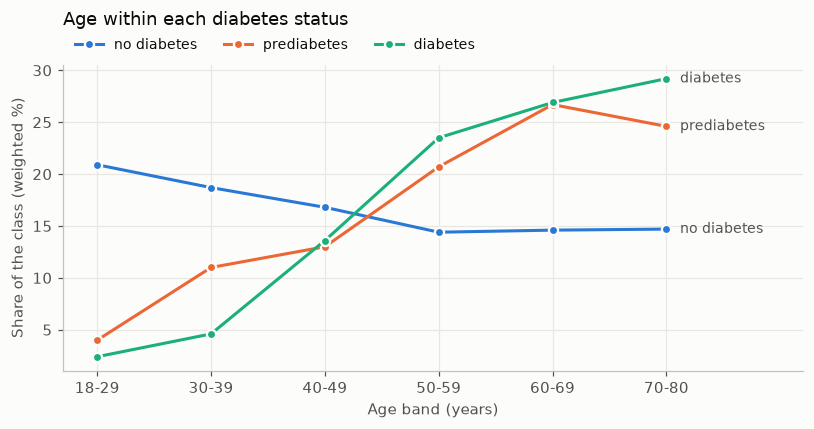

In [4]:
def band_chart(table, xlabel, title, filename):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    x = np.arange(len(table.index))
    for cls in CLASS_ORDER:
        ax.plot(x, table[cls], color=CLASS_COLORS[cls], linewidth=2, marker="o", markersize=6,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=cls.replace("_", " "))
    # Direct labels at the line ends, nudged apart so they never overlap.
    ends = sorted(CLASS_ORDER, key=lambda c: table[c].iloc[-1])
    min_gap = (table.max().max() - table.min().min()) * 0.06
    placed = []
    for cls in ends:
        y = table[cls].iloc[-1]
        if placed and y - placed[-1] < min_gap:
            y = placed[-1] + min_gap
        placed.append(y)
        ax.annotate(cls.replace("_", " "), (x[-1] + 0.12, y), va="center", fontsize=9, color="#52514e")
    ax.set_xticks(x, table.index)
    ax.set_xlim(-0.3, len(x) - 1 + 1.2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share of the class (weighted %)")
    ax.set_title(title, loc="left", pad=26)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(FIGURES / filename)
    plt.show()

band_chart(age_dist, "Age band (years)", "Age within each diabetes status", "rel_age_by_class.png")

## BMI

In [5]:
bmi_dist = pd.DataFrame({
    cls: 100 * weighted_distribution(df.loc[df["target"] == cls, "bmi_band"], df.loc[df["target"] == cls, "survey_weight"])
    for cls in CLASS_ORDER
}).round(1)
bmi_dist

,no_diabetes,prediabetes,diabetes
bmi_band,,,
under 18.5,2.3,0.7,0.5
18.5-24.9,32.7,21.6,14.8
25-29.9,35.2,33.4,32.2
30-34.9,18.4,23.2,26.0
35-39.9,6.8,8.6,13.2
40+,4.6,12.6,13.4


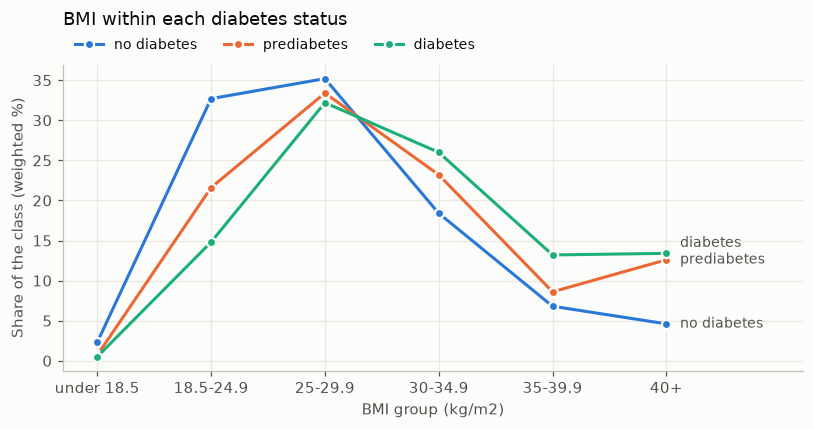

In [6]:
band_chart(bmi_dist, "BMI group (kg/m2)", "BMI within each diabetes status", "rel_bmi_by_class.png")

## Exercise

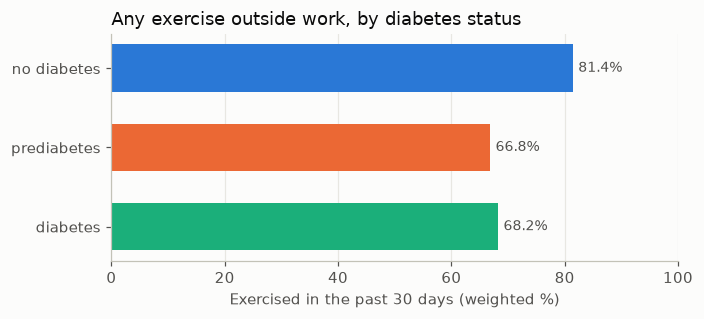

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3))
labels = [c.replace("_", " ") for c in CLASS_ORDER][::-1]
values = summary.loc[CLASS_ORDER[::-1], "exercise_pct"]
ax.barh(labels, values, color=[CLASS_COLORS[c] for c in CLASS_ORDER[::-1]], height=0.6)
for y, v in enumerate(values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 100)
ax.set_xlabel("Exercised in the past 30 days (weighted %)")
ax.set_title("Any exercise outside work, by diabetes status", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "rel_exercise_by_class.png")
plt.show()

In [8]:
# Exercise by age band, to check whether the gap is only an age effect.
ex_by_age = pd.DataFrame({
    cls: {
        band: 100 * weighted_share(g["any_exercise"], g["survey_weight"])
        for band, g in df[df["target"] == cls].groupby("age_band", observed=False)
    }
    for cls in CLASS_ORDER
}).round(1)
ex_by_age

,no_diabetes,prediabetes,diabetes
18-29,83.7,54.5,86.6
30-39,82.2,54.8,74.4
40-49,81.9,79.5,70.8
50-59,83.5,61.7,67.0
60-69,82.2,57.1,68.2
70-80,73.8,82.1,65.4


In [9]:
# Interviews behind each cell. Prediabetes has fewer than 70 people in each band under 40,
# so its exercise rates by age are noisy and are not used in the write-up.
pd.crosstab(df["age_band"], df["target"])[CLASS_ORDER]

target,no_diabetes,prediabetes,diabetes
age_band,,,
18-29,4436,45,76
30-39,4665,67,183
40-49,4860,119,480
50-59,5177,163,989
60-69,6390,256,1650
70-80,7883,301,2260


## Height and weight track BMI

BMI is weight divided by height squared, and BRFSS computes `_BMI5` from these same two answers. If BMI is already in the model, adding height and weight repeats the same information.

In [10]:
hw = df.dropna(subset=["bmi", "height_cm", "weight_kg"])
bmi_from_hw = hw["weight_kg"] / (hw["height_cm"] / 100) ** 2
print(f"Rows with all three: {len(hw):,}")
print(f"Correlation of rebuilt BMI with reported BMI: {bmi_from_hw.corr(hw['bmi']):.4f}")
print(f"Largest gap: {(bmi_from_hw - hw['bmi']).abs().max():.2f}")
print(f"Correlation of weight with BMI: {hw['weight_kg'].corr(hw['bmi']):.2f}")
print(f"Correlation of height with BMI: {hw['height_cm'].corr(hw['bmi']):.2f}")

Rows with all three: 37,618
Correlation of rebuilt BMI with reported BMI: 1.0000
Largest gap: 0.11
Correlation of weight with BMI: 0.86
Correlation of height with BMI: -0.03


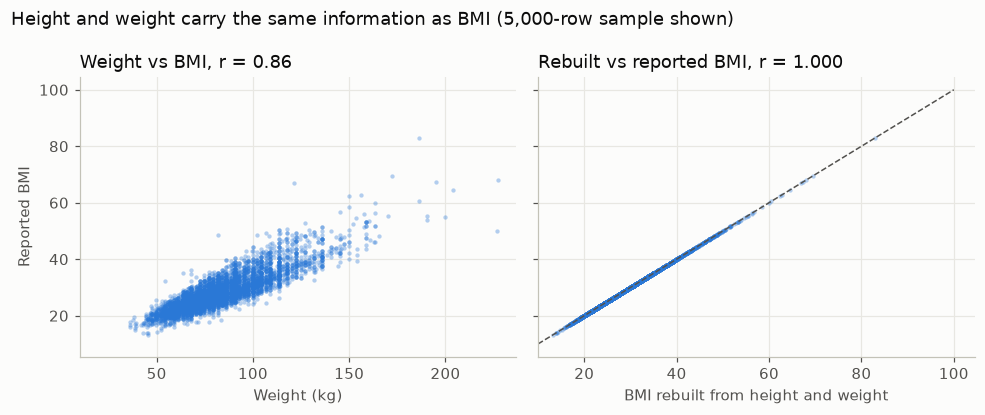

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
sample = hw.sample(5000, random_state=0)
axes[0].scatter(sample["weight_kg"], sample["bmi"], s=8, alpha=0.35, color="#2a78d6", linewidths=0)
axes[0].set_xlabel("Weight (kg)")
axes[0].set_ylabel("Reported BMI")
axes[0].set_title(f"Weight vs BMI, r = {hw['weight_kg'].corr(hw['bmi']):.2f}", loc="left")
rebuilt = sample["weight_kg"] / (sample["height_cm"] / 100) ** 2
axes[1].scatter(rebuilt, sample["bmi"], s=8, alpha=0.35, color="#2a78d6", linewidths=0)
axes[1].plot([10, 100], [10, 100], color="#52514e", linewidth=1, linestyle="--")
axes[1].set_xlabel("BMI rebuilt from height and weight")
axes[1].set_title(f"Rebuilt vs reported BMI, r = {bmi_from_hw.corr(hw['bmi']):.3f}", loc="left")
for ax in axes:
    ax.set_xlim(left=10)
fig.suptitle("Height and weight carry the same information as BMI (5,000-row sample shown)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "rel_height_weight_vs_bmi.png")
plt.show()